---
format:
  html: default
---

# Midterm study guide {.unnumbered}

The midterm (**Wed 28 Oct, 9:15–10:45**) covers **Lectures 1–11**. This page lists the topics you should know and gives some worked numerical examples. You will be allowed **two sides of letter** of your own notes. Calculators and computers are **not** allowed.

**How to revise.**

* Read through the lecture notes and make sure you can state the definitions and theorems *and* use them on examples by hand.
* Practice with the [exercise bank](../exercises/bank.html): you can go through it lecture by lecture. It also contains Quizzes 0–3 and the **Fall 2025 midterm**, all with solutions.

## Errors and rates of convergence (Lecture 1)

* Absolute and relative errors.
* Big-O notation: $x_n = O(\varepsilon_n)$ as $n \to \infty$ means $|x_n| \leq C |\varepsilon_n|$ for some $C$ and all $n$ large enough.
* *Algebraic* convergence $O(n^{-\alpha})$ (a straight line with slope $-\alpha$ on a **log-log** plot) vs *exponential* convergence $O(e^{-cn})$ (a straight line on a **semi-log** plot).


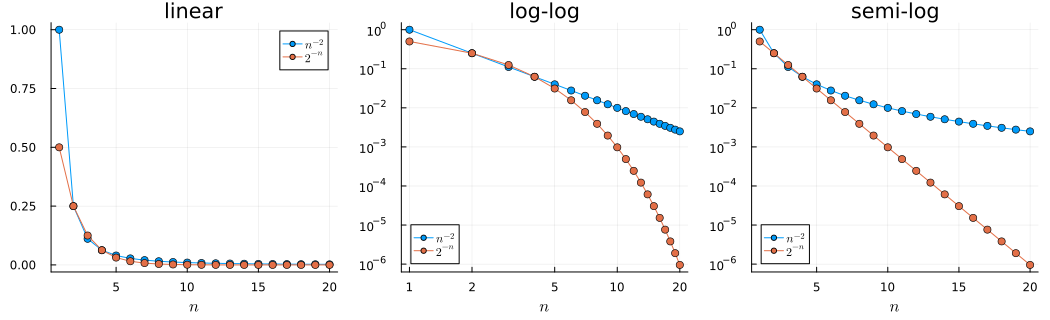

In [ ]:
using Plots, LaTeXStrings, Printf

n = 1:20
errs = [ (@. 1 / n^2) (@. 2.0^(-n)) ]
p0 = plot(n, errs; 
    marker=:circle, label=[L"n^{-2}" L"2^{-n}"], 
    title="linear", xlabel=L"n")
p1 = plot(n, errs; 
    xaxis=:log, yaxis=:log, marker=:circle, 
    label=[L"n^{-2}" L"2^{-n}"], title="log-log", xlabel=L"n",
    xticks=([1, 2, 5, 10, 20], ["1", "2", "5", "10", "20"]))
p2 = plot(n, errs; 
    yaxis=:log, marker=:circle, label=[L"n^{-2}" L"2^{-n}"], 
    title="semi-log", xlabel=L"n")
plot(p0, p1, p2, layout=(1, 3), size=(1050, 320), legend=[:topright :bottomleft :bottomleft], bottom_margin=5Plots.mm)

On the linear plot, both errors just look like they go to $0$, so you can't tell the rates apart. The algebraic error $n^{-2}$ is a straight line (slope $-2$) on the log-log plot, and the exponential error $2^{-n}$ is a straight line on the semi-log plot. On the "wrong" plot, each one curves.

## Floating point arithmetic (Lecture 2)

* Binary representation; floating point numbers with binary precision $k$: the numbers in $[2^n, 2^{n+1})$ are $(1 + z 2^{-k}) 2^n$ for $z = 0, 1, \dots, 2^k - 1$, so they are spaced $2^{n-k}$ apart.
* Machine precision $\epsilon_{\rm mach} = 2^{-k}$ (for `Float64`, $k = 52$ and `eps()` $= 2^{-52} \approx 2.2 \times 10^{-16}$).
* Rounding: $\mathrm{fl}(x) = x(1 + \delta)$ with $|\delta| \leq \frac12 \epsilon_{\rm mach}$; which numbers are exactly representable; why $1 + x$ can return exactly $1$.

**Example 1.** Consider floating point numbers with binary precision $k = 4$.

1. What is the spacing of the floating point numbers in $[2, 4)$? What is $\epsilon_{\rm mach}$?
2. Are $2.625$, $2.6$ and $3.0625$ floating point numbers?

::: {.callout-tip collapse="true"}
## Answer

1. Here $n = 1$, so the spacing is $2^{1 - 4} = \frac18$ (the numbers are $2, 2.125, 2.25, \dots, 3.875$), and $\epsilon_{\rm mach} = 2^{-4} = \frac1{16}$.
2. $2.625 = 2 + \frac58$ is a multiple of $\frac18$, so it is a floating point number ($2.625 = (1.0101)_2 \times 2^1$). $2.6$ is not: $0.6$ has an infinite binary expansion. $3.0625 = 3 + \frac1{16}$ is not a multiple of $\frac18$ ($3.0625 = (1.10001)_2 \times 2^1$ needs $5$ binary digits after the point).

:::

In [2]:
println("eps() = ", eps(), " = 2^-52 = ", 2.0^-52)
println("1 + 2^-54 == 1:    ", 1 + 2.0^-54 == 1)
println("1 + 2^-52 == 1:    ", 1 + 2.0^-52 == 1)
println("0.1 + 0.2 == 0.3:  ", 0.1 + 0.2 == 0.3)
println("spacing of the floats near 2^60: ", eps(2.0^60))

eps() = 2.220446049250313e-16 = 2^-52 = 2.220446049250313e-16
1 + 2^-54 == 1:    true
1 + 2^-52 == 1:    false
0.1 + 0.2 == 0.3:  false
spacing of the floats near 2^60: 256.0


## Conditioning and stability (Lecture 3)

* The relative condition number $\kappa_f(x) = \left| \frac{x f'(x)}{f(x)} \right|$; well-conditioned vs ill-conditioned problems.
* Conditioning is a property of the **problem**; stability is a property of the **algorithm**. A well-conditioned problem can still be computed badly by an unstable algorithm.
* Subtractive cancellation (subtracting nearly equal numbers) and how to avoid it by rewriting the formula.

**Example 2.**

1. Compute $\kappa_f(x)$ for $f(x) = \log x$ and $f(x) = e^x$. Where are these problems ill-conditioned?
2. Let $f(x) = \frac{1 - \cos x}{x^2}$. Show that $f(x) = \frac{2 \sin^2(x/2)}{x^2}$. Which formula should you use for small $x$? (See the table below.)

::: {.callout-tip collapse="true"}
## Answer

1. For $f(x) = \log x$: $\kappa_f(x) = \left| \frac{x \cdot \frac1x}{\log x} \right| = \frac{1}{|\log x|}$, which is large near $x = 1$ (where $\log x \approx 0$). For $f(x) = e^x$: $\kappa_f(x) = \left| \frac{x e^x}{e^x} \right| = |x|$, which is large only for large $|x|$.
2. $1 - \cos x = 2 \sin^2 \frac{x}{2}$ (double angle formula). For small $x$, $\cos x \approx 1$, so $1 - \cos x$ suffers from subtractive cancellation: for $x = 10^{-8}$, `cos(x)` is exactly `1.0` and the first formula returns $0$. The second formula has no cancellation and gives $\approx \frac12$, which is correct ($f(x) = \frac12 - \frac{x^2}{24} + \dots$). The problem itself is well-conditioned ($\kappa_f(x) \approx \frac{x^2}{12}$ for small $x$): only the first *algorithm* is unstable.

:::

In [3]:
for x in [1e-2, 1e-5, 1e-8]
    @printf("x = %.0e:   (1 - cos x)/x^2 = %.16f,   2 sin^2(x/2)/x^2 = %.16f\n",
            x, (1 - cos(x)) / x^2, 2 * sin(x/2)^2 / x^2)
end

x = 1e-02:   (1 - cos x)/x^2 = 0.4999958333473664,   2 sin^2(x/2)/x^2 = 0.4999958333472221
x = 1e-05:   (1 - cos x)/x^2 = 0.5000000413701854,   2 sin^2(x/2)/x^2 = 0.4999999999958333
x = 1e-08:   (1 - cos x)/x^2 = 0.0000000000000000,   2 sin^2(x/2)/x^2 = 0.5000000000000000


## Simple iterations (Lecture 4)

* The change of sign (intermediate value) theorem for the existence of a root; 
* Fixed points $\xi = g(\xi)$ and the iteration $x_{n+1} = g(x_n)$.
* Contractions ($|g(x) - g(y)| \leq L|x - y|$ with $L < 1$); using the mean value theorem to show that $g$ is a contraction ($|g'| \leq L < 1$); checking that $g$ maps $[a,b]$ to $[a,b]$.
* The contraction mapping theorem, and the bound $|x_{n+1} - \xi| \leq L^n |x_1 - \xi|$.
* Order of convergence $\alpha$ and asymptotic error constant $\mu$: $\frac{|x_{n+1} - \xi|}{|x_n - \xi|^\alpha} \to \mu$. For simple iteration, $\mu = |g'(\xi)|$ (linear convergence if $0 < |g'(\xi)| < 1$).
* Stable ($|g'(\xi)| < 1$) and unstable ($|g'(\xi)| > 1$) fixed points.

**Example 3.** Show that $f(x) = e^x - 3x$ has exactly one root in $[0,1]$.

::: {.callout-tip collapse="true"}
## Answer

$f$ is continuous with $f(0) = 1 > 0$ and $f(1) = e - 3 < 0$, so by the change of sign theorem it has a root in $(0,1)$. Moreover, $f'(x) = e^x - 3 \leq e - 3 < 0$ on $[0,1]$, so $f$ is strictly decreasing and has at most one root.

:::

**Example 4.** Let $g(x) = \frac{1}{1+x}$ and $I = [\frac12, 1]$.

1. Show that $g$ maps $I$ to $I$ and is a contraction on $I$. Find its fixed point $\xi$.
2. How many iterations guarantee $|x_{n+1} - \xi| \leq 10^{-6}$ for every $x_1 \in I$?
3. What are the order of convergence and the asymptotic error constant? Compare with the table below.

::: {.callout-tip collapse="true"}
## Answer

1. $g$ is decreasing on $I$ with $g(\frac12) = \frac23$ and $g(1) = \frac12$, so $g(I) = [\frac12, \frac23] \subseteq I$. Moreover, $|g'(x)| = \frac{1}{(1+x)^2} \leq \frac{1}{(3/2)^2} = \frac49$ on $I$, so (by the mean value theorem) $g$ is a contraction with $L = \frac49$. The fixed point solves $\xi(1 + \xi) = 1$, i.e. $\xi^2 + \xi - 1 = 0$, so $\xi = \frac{\sqrt5 - 1}{2} \approx 0.618$.
2. $|x_{n+1} - \xi| \leq L^n |x_1 - \xi| \leq \left(\frac49\right)^n \cdot \frac12$, which is at most $10^{-6}$ when $n \geq \frac{\log(2 \times 10^{-6})}{\log(4/9)} \approx 16.2$, i.e. $n = 17$.
3. Linear convergence with $\mu = |g'(\xi)| = \frac{1}{(1 + \xi)^2} = \xi^2 \approx 0.382$ (using $\frac{1}{1+\xi} = \xi$). The ratios in the table converge to $0.382$, which is better than $L = \frac49$, so in practice fewer iterations are needed than the bound in 2 says.

:::

In [4]:
g = x -> 1 / (1 + x)
ξ = (sqrt(5) - 1) / 2
x = 1.0
for n in 1:12
    xnew = g(x)
    @printf("n = %2d:  x_n = %.12f,  |x_n - ξ| = %.2e,  |x_{n+1} - ξ|/|x_n - ξ| = %.4f\n",
            n, x, abs(x - ξ), abs(xnew - ξ) / abs(x - ξ))
    global x = xnew
end
println("μ = |g'(ξ)| = ξ^2 = ", ξ^2)

n =  1:  x_n = 1.000000000000,  |x_n - ξ| = 3.82e-01,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3090
n =  2:  x_n = 0.500000000000,  |x_n - ξ| = 1.18e-01,  |x_{n+1} - ξ|/|x_n - ξ| = 0.4120
n =  3:  x_n = 0.666666666667,  |x_n - ξ| = 4.86e-02,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3708
n =  4:  x_n = 0.600000000000,  |x_n - ξ| = 1.80e-02,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3863
n =  5:  x_n = 0.625000000000,  |x_n - ξ| = 6.97e-03,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3803
n =  6:  x_n = 0.615384615385,  |x_n - ξ| = 2.65e-03,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3826
n =  7:  x_n = 0.619047619048,  |x_n - ξ| = 1.01e-03,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3817
n =  8:  x_n = 0.617647058824,  |x_n - ξ| = 3.87e-04,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3821
n =  9:  x_n = 0.618181818182,  |x_n - ξ| = 1.48e-04,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3819
n = 10:  x_n = 0.617977528090,  |x_n - ξ| = 5.65e-05,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3820
n = 11:  x_n = 0.618055555556,  |x_n - ξ| = 2.16e-05,  |x_{n+1} - ξ|/|x_n - ξ| = 0.3820
n = 12:  x_n = 0.618025751073,  

## Relaxation, Newton's method and the secant method (Lecture 5)

* The relaxation method $x_{n+1} = x_n - \lambda f(x_n)$: when it converges and how to choose $\lambda$.
* Newton's method $x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$: derivation from the tangent line, quadratic convergence with $\mu = \frac12 \left| \frac{f''(\xi)}{f'(\xi)} \right|$, the convergence theorem (with the constant $A$), and what can go wrong ($f'(x_n) = 0$, cycles, starting too far away).
* The secant method and its order of convergence $\frac{1 + \sqrt5}{2} \approx 1.618$.
* Recognising the order of convergence from a table of errors (the number of correct digits roughly doubles each step for quadratic convergence).

**Example 5.** Let $f(x) = x^2 - 3$ (so $\xi = \sqrt3$).

1. Compute two steps of Newton's method with $x_1 = 2$.
2. What is the asymptotic error constant? Compare with the table below.
3. For which $\lambda$ does the relaxation method converge for $x_1$ close to $\sqrt3$? Which $\lambda$ gives faster than linear convergence?

::: {.callout-tip collapse="true"}
## Answer

1. $x_{n+1} = x_n - \frac{x_n^2 - 3}{2x_n} = \frac12\left(x_n + \frac{3}{x_n}\right)$, so $x_2 = \frac12(2 + \frac32) = \frac74 = 1.75$ and $x_3 = \frac12\left(\frac74 + \frac{12}{7}\right) = \frac{97}{56} \approx 1.732143$ (compare $\sqrt3 \approx 1.732051$).
2. $\mu = \frac12 \left| \frac{f''(\xi)}{f'(\xi)} \right| = \frac12 \cdot \frac{2}{2\sqrt3} = \frac{1}{2\sqrt3} \approx 0.289$, which matches the ratios $|x_{n+1} - \xi|/|x_n - \xi|^2$ in the table.
3. Relaxation is simple iteration with $g(x) = x - \lambda(x^2 - 3)$ and $g'(\sqrt3) = 1 - 2\sqrt3 \lambda$. It converges for $x_1$ close to $\sqrt 3$ if $|1 - 2\sqrt3\lambda| < 1$, i.e. $0 < \lambda < \frac{1}{\sqrt3}$, and the convergence is faster than linear when $g'(\sqrt3) = 0$, i.e. $\lambda = \frac{1}{2\sqrt3}$.

:::

In [5]:
f  = x -> x^2 - 3
df = x -> 2x
ξ  = sqrt(3)

println("Newton's method, x_1 = 2:")
x = 2.0
for n in 1:3
    xnew = x - f(x) / df(x)
    @printf("  n = %d:  x_n = %.15f,  |x_n - ξ| = %.2e,  |x_{n+1} - ξ|/|x_n - ξ|^2 = %.4f\n",
            n, x, abs(x - ξ), abs(xnew - ξ) / abs(x - ξ)^2)
    global x = xnew
end

println("Secant method, x_0 = 1, x_1 = 2:")
x0, x1 = 1.0, 2.0
for n in 1:6
    x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))
    @printf("  n = %d:  x_n = %.15f,  |x_n - ξ| = %.2e\n", n, x1, abs(x1 - ξ))
    global x0, x1 = x1, x2
end

Newton's method, x_1 = 2:
  n = 1:  x_n = 2.000000000000000,  |x_n - ξ| = 2.68e-01,  |x_{n+1} - ξ|/|x_n - ξ|^2 = 0.2500
  n = 2:  x_n = 1.750000000000000,  |x_n - ξ| = 1.79e-02,  |x_{n+1} - ξ|/|x_n - ξ|^2 = 0.2857
  n = 3:  x_n = 1.732142857142857,  |x_n - ξ| = 9.20e-05,  |x_{n+1} - ξ|/|x_n - ξ|^2 = 0.2887
Secant method, x_0 = 1, x_1 = 2:
  n = 1:  x_n = 2.000000000000000,  |x_n - ξ| = 2.68e-01
  n = 2:  x_n = 1.666666666666667,  |x_n - ξ| = 6.54e-02
  n = 3:  x_n = 1.727272727272727,  |x_n - ξ| = 4.78e-03
  n = 4:  x_n = 1.732142857142857,  |x_n - ξ| = 9.20e-05
  n = 5:  x_n = 1.732050680431722,  |x_n - ξ| = 1.27e-07
  n = 6:  x_n = 1.732050807565499,  |x_n - ξ| = 3.38e-12


## Polynomial interpolation (Lectures 6–9)

**Lecture 6.**

* Existence and uniqueness of the interpolant $I_Xf \in \mathcal P_n$ on $n + 1$ distinct nodes (and why two interpolants $p, q \in \mathcal P_n$ must be equal).
* The Lagrange polynomials $\ell_j$ and the Lagrange form $I_Xf = \sum_j f(x_j) \ell_j$.
* The interpolation error formula $f(x) - I_Xf(x) = \frac{f^{(n+1)}(\xi_x)}{(n+1)!} \ell_X(x)$ with the node polynomial $\ell_X(x) = (x - x_0) \cdots (x - x_n)$, and using it to bound the error.
* The Runge phenomenon for equispaced nodes.

**Lecture 7.**

* Chebyshev polynomials: $T_n(\cos\theta) = \cos n\theta$, the recursion $T_{n+1} = 2xT_n - T_{n-1}$, the leading coefficient $2^{n-1}$, the zeros and extrema of $T_n$.
* Chebyshev nodes (zeros or extrema of $T_n$), $\max_{[-1,1]} |\ell_X| = 2^{-n}$ for the zeros of $T_{n+1}$, and why Chebyshev nodes are a good choice. Mapping nodes from $[-1,1]$ to $[a,b]$.

**Lecture 8.**

* The barycentric formula and the barycentric weights $\lambda_j = \frac{1}{\prod_{k \not= j}(x_j - x_k)}$ (and why we can rescale the weights).
* Divided differences: the table, the Newton form $I_Xf(x) = \sum_k f[x_0, \dots, x_k] (x - x_0) \cdots (x - x_{k-1})$, and the properties of divided differences (symmetric in the nodes, linear in $f$, $f[x_0, \dots, x_n]$ is the leading coefficient of $I_Xf$, so it vanishes when $f \in \mathcal P_{n-1}$).

**Lecture 9.**

* Hermite interpolation on multisets of nodes (matching derivatives at repeated nodes), $f[x_0, \dots, x_0] = \frac{f^{(m)}(x_0)}{m!}$ ($m + 1$ copies), and the Hermite error formula.

**Example 6.** Let $f(x) = \frac{1}{1 + x}$ and $X = \{0, 1, 2\}$.

1. Write down $I_Xf$ in Lagrange form.
2. Compute the divided difference table and write down $I_Xf$ in Newton form.
3. Compute the barycentric weights.
4. Compare $I_Xf(1.5)$ with $f(1.5)$ and with the error formula.

::: {.callout-tip collapse="true"}
## Answer

1. $\ell_0(x) = \frac{(x-1)(x-2)}{2}$, $\ell_1(x) = -x(x-2)$, $\ell_2(x) = \frac{x(x-1)}{2}$, and $I_Xf = \ell_0 + \frac12 \ell_1 + \frac13 \ell_2$.
2. The table is
$$
\begin{array}{c|ccc}
    x_j & f(x_j) & \text{1st} & \text{2nd} \\ \hline
    0 & 1 & & \\
      & & -\frac12 & \\
    1 & \frac12 & & \frac16 \\
      & & -\frac16 & \\
    2 & \frac13 & &
\end{array}
$$
so $I_Xf(x) = 1 - \frac12 x + \frac16 x(x-1)$.
3. $\lambda_0 = \frac{1}{(0-1)(0-2)} = \frac12$, $\lambda_1 = \frac{1}{(1-0)(1-2)} = -1$, $\lambda_2 = \frac{1}{(2-0)(2-1)} = \frac12$.
4. $I_Xf(1.5) = 1 - 0.75 + 0.125 = 0.375$ and $f(1.5) = 0.4$, so the error is $0.025$. Since $f^{(3)}(x) = -\frac{6}{(1+x)^4}$, we have $|f^{(3)}| \leq 6$ on $[0,2]$, and the error formula gives $|f(1.5) - I_Xf(1.5)| \leq \frac{6}{3!} |1.5 \cdot 0.5 \cdot (-0.5)| = 0.375$. (The bound holds, but it is pessimistic because $|f^{(3)}|$ is much smaller than $6$ away from $x = 0$.)

:::

**Example 7.** Compare the node polynomials for $4$ equispaced nodes $\{-1, -\frac13, \frac13, 1\}$ and for the $4$ Chebyshev nodes (the zeros of $T_4$) on $[-1,1]$.

::: {.callout-tip collapse="true"}
## Answer

For the Chebyshev nodes, $\ell_X = 2^{-3} T_4$ and so $\max_{[-1,1]} |\ell_X| = \frac18 = 0.125$. For the equispaced nodes, $\ell_X(x) = (x^2 - 1)(x^2 - \frac19)$. With $y = x^2 \in [0,1]$, $h(y) = (y - 1)(y - \frac19)$ has $h'(y) = 2y - \frac{10}{9} = 0$ at $y = \frac59$, where $|h| = \frac49 \cdot \frac49 = \frac{16}{81} \approx 0.198$; at the end points $|h(0)| = \frac19$ and $h(1) = 0$. So $\max |\ell_X| = \frac{16}{81}$, which is about $1.6$ times larger than for the Chebyshev nodes. The difference grows exponentially with $n$ (see the Runge example below).

:::

**Example 8 (the Runge phenomenon).** The maximum interpolation error of $f(x) = \frac{1}{1 + 25x^2}$ on $[-1,1]$ using the barycentric formula with $n+1$ equispaced or Chebyshev nodes:

In [6]:
function barycentric(x, y, t)
    λ = [ 1 / prod(x[j] - x[k] for k in eachindex(x) if k != j) for j in eachindex(x) ]
    i = findfirst(==(t), x)
    i === nothing || return y[i]
    s = λ ./ (t .- x)
    return sum(s .* y) / sum(s)
end

Runge = x -> 1 / (1 + 25x^2)
grid = range(-1, 1, length=2001)
for n in 4:4:24
    xe = range(-1, 1, length=n+1)
    xc = @. cos(π * (0:n) / n)
    Ee = maximum(abs(barycentric(xe, Runge.(xe), t) - Runge(t)) for t in grid)
    Ec = maximum(abs(barycentric(xc, Runge.(xc), t) - Runge(t)) for t in grid)
    @printf("n = %2d:  equispaced error = %.2e,  Chebyshev error = %.2e\n", n, Ee, Ec)
end

n =  4:  equispaced error = 4.38e-01,  Chebyshev error = 4.60e-01
n =  8:  equispaced error = 1.05e+00,  Chebyshev error = 2.05e-01
n = 12:  equispaced error = 3.66e+00,  Chebyshev error = 8.44e-02
n = 16:  equispaced error = 1.44e+01,  Chebyshev error = 3.67e-02
n = 20:  equispaced error = 5.98e+01,  Chebyshev error = 1.77e-02
n = 24:  equispaced error = 2.57e+02,  Chebyshev error = 8.17e-03


**Example 9 (Hermite interpolation).** Find $p \in \mathcal P_3$ with $p(0) = 0$, $p'(0) = 1$, $p(1) = 1$ and $p'(1) = 0$.

::: {.callout-tip collapse="true"}
## Answer

Use the nodes $\{\{0, 0, 1, 1\}\}$ with $f[0,0] = p'(0) = 1$ and $f[1,1] = p'(1) = 0$:
$$
\begin{array}{c|cccc}
    x_j & f(x_j) & \text{1st} & \text{2nd} & \text{3rd} \\ \hline
    0 & 0 & & & \\
      & & 1 & & \\
    0 & 0 & & 0 & \\
      & & 1 & & -1 \\
    1 & 1 & & -1 & \\
      & & 0 & & \\
    1 & 1 & & &
\end{array}
$$
($f[0,1] = \frac{1 - 0}{1 - 0} = 1$, $f[0,0,1] = \frac{1 - 1}{1} = 0$, $f[0,1,1] = \frac{0 - 1}{1} = -1$, $f[0,0,1,1] = \frac{-1 - 0}{1} = -1$.) So $p(x) = 0 + 1 \cdot x + 0 \cdot x^2 - x^2(x-1) = x + x^2 - x^3$. Check: $p(1) = 1$ and $p'(1) = 1 + 2 - 3 = 0$.

:::

## Quadrature (Lectures 10–11)

* Interpolatory quadrature: $\int_a^b f \approx \sum_j w_j f(x_j)$ with $w_j = \int_a^b \ell_j$; the rule is exact on $\mathcal P_n$ if and only if it is interpolatory; the weights sum to $b - a$; finding weights from exactness on $1, x, x^2, \dots$,
* Newton–Cotes rules: the rectangular, trapezoid and Simpson's rules, and their degrees of exactness (Simpson's rule is exact for cubics).
* How to obtain error bounds, e.g. $\frac{(b-a)^3}{12} \|f''\|$ for the trapezoid rule and $\frac{(b-a)^5}{2880} \|f^{(4)}\|$ for Simpson's rule,
* Composite rules with $n$ subintervals: rates $O(n^{-1})$ (rectangular), $O(n^{-2})$ (trapezoid) and $O(n^{-4})$ (Simpson, $n$ even),

**Example 10.** Let $I = \int_0^1 \frac{1}{1+x} \, \mathrm{d}x = \log 2 \approx 0.693147$.

1. Approximate $I$ with the rectangular rule $(b-a) f(a)$, the trapezoid rule and Simpson's rule.
2. How many subintervals guarantee an error of at most $10^{-6}$ for the composite trapezoid rule? And for the composite Simpson rule?
3. Find $w_0, w_1$ such that $\int_0^1 f \approx w_0 f(\frac14) + w_1 f(\frac34)$ is exact on $\mathcal P_1$. Is it exact for $x^2$?

::: {.callout-tip collapse="true"}
## Answer

1. Rectangular: $f(0) = 1$. Midpoint: $f(\frac12) = \frac23 \approx 0.6667$. Trapezoid: $\frac12(1 + \frac12) = 0.75$. Simpson: $\frac16\left(1 + 4 \cdot \frac23 + \frac12\right) = \frac{25}{36} \approx 0.69444$ (error $\approx 1.3 \times 10^{-3}$).
2. $f''(x) = \frac{2}{(1+x)^3} \leq 2$ and $f^{(4)}(x) = \frac{24}{(1+x)^5} \leq 24$ on $[0,1]$. Trapezoid: $\frac{2}{12 n^2} \leq 10^{-6}$ when $n^2 \geq \frac{10^6}{6}$, i.e. $n \geq 409$. Simpson: $\frac{24}{180 n^4} \leq 10^{-6}$ when $n^4 \geq \frac{2 \times 10^6}{15} \approx 1.33 \times 10^5$, i.e. $n \geq 19.1$, so $n = 20$ (even).
3. Exactness for $1$ and $x$: $w_0 + w_1 = 1$ and $\frac14 w_0 + \frac34 w_1 = \frac12$, so $w_0 = w_1 = \frac12$. For $x^2$: $\frac12\left(\frac1{16} + \frac9{16}\right) = \frac{5}{16} \not= \frac13$, so it is not exact for $x^2$.

:::

In [7]:
f = x -> 1 / (1 + x)
I = log(2)
rectangular(f, a, b, n) = (h = (b - a) / n; h * sum(f(a + j*h) for j in 0:n-1))
trapezoid(f, a, b, n)   = (h = (b - a) / n; h * (f(a)/2 + sum((f(a + j*h) for j in 1:n-1); init=0.0) + f(b)/2))
simpson(f, a, b, n)     = (h = (b - a) / n; h/3 * (f(a) + 4sum(f(a + j*h) for j in 1:2:n-1)
                                                   + 2sum((f(a + j*h) for j in 2:2:n-2); init=0.0) + f(b)))

println("errors of the composite rules for ∫_0^1 1/(1+x) dx:")
for n in [2, 4, 8, 16, 32, 64]
    @printf("  n = %2d:  rectangular %.2e,  trapezoid %.2e,  Simpson %.2e\n", n,
            abs(rectangular(f, 0, 1, n) - I), abs(trapezoid(f, 0, 1, n) - I), abs(simpson(f, 0, 1, n) - I))
end

errors of the composite rules for ∫_0^1 1/(1+x) dx:
  n =  2:  rectangular 1.40e-01,  trapezoid 1.52e-02,  Simpson 1.30e-03
  n =  4:  rectangular 6.64e-02,  trapezoid 3.88e-03,  Simpson 1.07e-04
  n =  8:  rectangular 3.22e-02,  trapezoid 9.75e-04,  Simpson 7.35e-06
  n = 16:  rectangular 1.59e-02,  trapezoid 2.44e-04,  Simpson 4.72e-07
  n = 32:  rectangular 7.87e-03,  trapezoid 6.10e-05,  Simpson 2.97e-08
  n = 64:  rectangular 3.92e-03,  trapezoid 1.53e-05,  Simpson 1.86e-09


Doubling $n$ divides the errors by about $2$, $4$ and $16$: the rates are $O(n^{-1})$, $O(n^{-2})$ and $O(n^{-4})$, as the theory predicts.